### Full dynesty run + visualization pipeline

The step-by-step validation of `dynesty_utils`: simulated data, the likelihood and its landscape, nested sampling with every insolation model, the evidence against a brute-force integral, and the posterior post-processing. `run_dynesty.py` is the batch version of 1.-3. and `01_retrieval_example.ipynb` reads its pickles back; this notebook keeps everything in one kernel. The three insolation models are fitted: `hyperillum` (the truth's), `naive` and `naive_redist`, the last one with the heat redistribution $F$ (Kreidberg & Loeb 2016) as a third free parameter.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from HItargets_utils import *
import fspiderman as sp
from dynesty import utils as dyfunc, plotting as dyplot
from hyperillumination_phasecurve_utils import *
from simple_bias_analysis import *
import time

In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

A_B_true = DEFAULT_A_B   # injected Bond albedo (baseline settings, HItargets_utils.py)

INSOL_TRUTH = "hyperillum"  # insolation model used to generate the simulated truth

A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

n_bins = DEFAULT_N_BINS # number of bins in one orbit
n_orbits = DEFAULT_N_ORBITS # number of orbits observed
sigma_1min = rms_1min(planet, instrument, lrs_range)   # detection error [ppm per minute] for the chosen band (PandExo, served from the cache)
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")

seed=42

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm/min from the PandExo cache (pandexo_cache.csv)

Noise Level (1min) = 62.9 ppm


In [3]:
l1, l2 = lrs_range

# context for simulating data functions
cfg = FittingConfig(planet=planet, filter_path=lrs_path, l1=l1, l2=l2, A_=A_model,
                    sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)

print(f"period = {planet.period*24*60:.1f} min -> {n_bins} bins of {planet.period*24*60/n_bins:.1f} min")
print(f"1-sigma per bin (over all orbits) = {cfg.sigma_bin:.1f} ppm")

period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin (over all orbits) = 8.1 ppm


### 1. Simulated Data

sigma_bin: 8.14 ppm  (bin width 11.96 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.63
residual mean / sigma (~0): -0.03


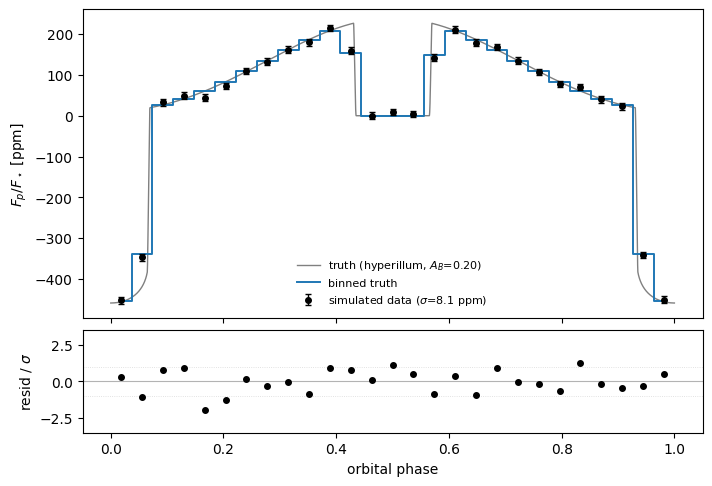

In [4]:
# SIMULATED OBSERVATION
data = simulate_data(cfg, A_B_true, insolation_model=INSOL_TRUTH)

### 2. Likelihood `GaussianLogL`

This is the object dynesty wants as `loglike`: a picklable, module-level callable `theta -> lnL`, where `theta` is ordered by `names` (that ordering is also the column order of `res.samples`). Anything `model_pcurve` needs that is *not* sampled goes into `fixed`.

$$\ln\mathcal{L}(\theta) = -\tfrac{1}{2}\sum_i\left[\left(\frac{y_i-m_i(\theta)}{s_i}\right)^2 + \ln\left(2\pi s_i^2\right)\right]$$

The $\ln(2\pi s^2)$ term is $\theta$-independent and cancels in Bayes factors on identical data, but keeping it makes $\ln Z$ a properly normalised evidence.

Two geometry-only caches are built automatically and are **bit-identical** to recomputing: `reflected_unit` (reflected light is exactly linear in $A$) and the insolation map ($T(A_B)=T(A_B{=}0)\,(1-A_B)^{1/4}$ exactly, so the order-64 penumbra integral is $A_B$-independent). Each is dropped as soon as a parameter it depends on is sampled — `logl.cache_used` says which survived. `naive_redist` has no insolation map to cache: its thermal curve is SPIDERMAN's analytic Louden model, and $F$ is a free parameter of that model alone (the likelihood refuses $F$ for the other two).

Each model is sampled with its own `ParameterSet`; `hyperillum` and `naive` share the $(A_B, \mathrm{offset})$ box, `naive_redist` adds $F$ with its physical prior `F_BOUNDS`. At the injected $F = 0$ `naive_redist` *is* the naive model, so its $\ln\mathcal{L}$ at the truth must agree with the naive one (printed below; the Louden curve and the `direct_T` grid differ by $\lesssim 0.03$ ppm).


In [5]:
N_JOBS = -1 # use every core

# ParameterSet holds everything about the free parameters: it fixes the column order of theta and of res.samples, supplies the dynesty ptform, carries the LaTeX labels, and hands evidence_bruteforce the same prior box the sampler used.
# Uniform priors over the shared ranges of HItargets_utils: the physical A_B_BOUNDS and F_BOUNDS, and OFFSET_BOUNDS. Each model is sampled with its OWN set (PSETS): only "naive_redist" has F.
_A_B    = Parameter("A_B",    Uniform(*A_B_BOUNDS), r"$A_B$")
_OFFSET = Parameter("offset", Uniform(*OFFSET_BOUNDS), "offset [ppm]")
_F      = Parameter("F",      Uniform(*F_BOUNDS), r"$F$")
pset  = ParameterSet((_A_B, _OFFSET))                                            # the (A_B, offset) box every model has - what the shared grids below are built on
PSETS = {"hyperillum": pset, "naive": pset, "naive_redist": ParameterSet((_A_B, _OFFSET, _F))}
MODELS = ("hyperillum", "naive", "naive_redist")

A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)
A_fine, O_fine = pset.grid("A_B", 201), pset.grid("offset", 401)
base  = dict(A_B=A_B_true, offset=0., F=0.) # the injected truth: no redistribution in the data, so F = 0 is the truth for naive_redist too
COLOR = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}
F_MODELS = [m for m in MODELS if "F" in PSETS[m].names]

# LogLikelihoods. Same data for every model, each with its own pset
logls = {m: GaussianLogL.from_pset(cfg, data, m, PSETS[m]) for m in MODELS}

for m, L in logls.items():
    th = theta_of(L, base)
    L(th)  # warm up
    t0 = time.perf_counter(); val = L(th); dt = time.perf_counter() - t0
    print(f"{L!r}   bounds {PSETS[m].bounds}")
    print(f"   lnL(truth) = {val:9.2f}   chi2 = {L.chi2(th):6.1f} / {cfg.n_bins} bins   {dt*1e3:6.0f} ms/call  ->  {dt*1e4/60:.0f} min per 1e4 calls (serial)")
d_ = logls["naive_redist"].model(theta_of(logls["naive_redist"], base)) - logls["naive"].model(theta_of(logls["naive"], base))
print(f"\nnaive_redist at F = 0 vs naive: max |difference| = {np.abs(d_).max():.4f} ppm  (Louden vs direct_T grid)")


GaussianLogL(hyperillum, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))   bounds [(0.0, 1.0), (-50.0, 50.0)]
   lnL(truth) =    -89.93   chi2 =   17.0 / 27 bins       62 ms/call  ->  10 min per 1e4 calls (serial)


GaussianLogL(naive, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))   bounds [(0.0, 1.0), (-50.0, 50.0)]
   lnL(truth) =   -124.36   chi2 =   85.9 / 27 bins       74 ms/call  ->  12 min per 1e4 calls (serial)
GaussianLogL(naive_redist, names=('A_B', 'offset', 'F'), fixed={}, ndim=3, caches=('refl',))   bounds [(0.0, 1.0), (-50.0, 50.0), (0.0, 0.5)]


   lnL(truth) =   -124.36   chi2 =   85.9 / 27 bins       49 ms/call  ->  8 min per 1e4 calls (serial)

naive_redist at F = 0 vs naive: max |difference| = 0.0210 ppm  (Louden vs direct_T grid)


#### 2.1 1-D slices

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$, so the dotted lines at $-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels. Scanning `offset` is free — it enters additively, so the whole slice comes from one forward model. Every other parameter is held at the injected truth, so in the $A_B$ and offset panels the `naive_redist` slice (at $F=0$) lies on top of the naive one (dashed). The $F$ panel is zoomed to where the likelihood is still on the panel (linear axis): the data respond to $F$ only $\propto F^{\sim 1.5}$ near 0 and then fall off fast.


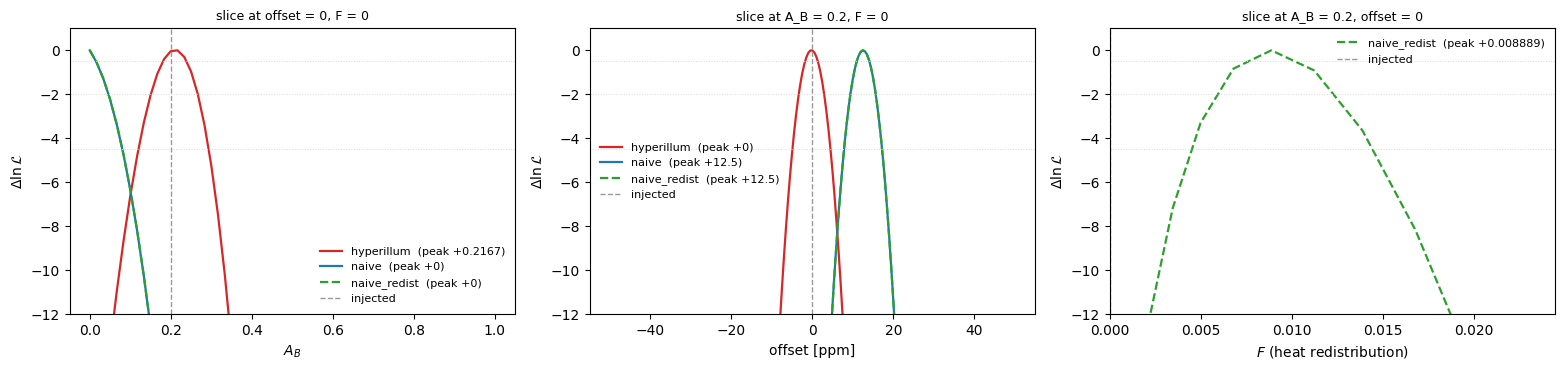

In [6]:
GRIDS  = {"A_B": A_grid, "offset": O_grid}   # one panel per parameter ANY model samples
if F_MODELS:   # F nodes over the full prior but quadratically dense towards 0, where the likelihood sits (the response to F is ~F^1.5 near 0 and the posterior is a sliver of the prior); the panel is zoomed below
    lo_F, hi_F = PSETS[F_MODELS[0]].bounds[PSETS[F_MODELS[0]].names.index("F")]
    GRIDS["F"] = lo_F + (hi_F - lo_F) * np.linspace(0., 1., 61) ** 2
XLABEL = {"A_B": "$A_B$", "offset": "offset [ppm]", "F": "$F$ (heat redistribution)"}
YLIM   = -12.

SLICES = {}
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5.25 * len(GRIDS), 3.8), squeeze=False)
for ax, (p, g) in zip(axes.ravel(), GRIDS.items()):
    for name, L in logls.items():
        if p not in L.names: continue                              # e.g. F, which only "naive_redist" has
        s = logl_slice(L, p, g, base, n_jobs=N_JOBS)               # one forward model per node, except "offset" (additive -> free)
        SLICES[p, name] = s
        ax.plot(g, s - s.max(), color=COLOR[name], lw=1.6, ls="--" if name == "naive_redist" else "-", label=f"{name}  (peak {g[s.argmax()]:+.4g})")
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(base[p], color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(XLABEL[p]); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(YLIM, 1.); ax.legend(frameon=False, fontsize=8)
    ax.set_title("slice at " + ", ".join(f"{q} = {base[q]:g}" for q in GRIDS if q != p), fontsize=9)
    if p == "F":   # zoom to where the curve is still on the panel (linear, never sqrt)
        on = np.concatenate([g[(SLICES[p, m] - SLICES[p, m].max()) > YLIM] for m in F_MODELS])
        F_LIM = (g[0], min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))   # from the prior floor F = 0 (the injected truth and the physical edge) up to where the curve leaves the panel; reused by the (A_B, F) map below
        ax.set_xlim(*F_LIM)
plt.tight_layout(); plt.show()


#### 2.2 2-D maps - the shape dynesty has to sample
With a **uniform** prior, $\exp(\ln\mathcal{L})$ over this box *is* the un-normalised posterior, so these maps are a direct preview of the corner plots the sampler should return. Contours are the 2-parameter $1/2/3\sigma$ levels ($\Delta\ln\mathcal{L}=-1.15,-3.09,-5.91$).

First the $(A_B, \mathrm{offset})$ box of every model (at $F = 0$ for `naive_redist`, where it coincides with the naive map). Then, for `naive_redist`, the $(A_B, F)$ plane the whole joint fit is about — how much albedo the fit trades for how much redistribution — with the offset **profiled out** (maximised per cell; free, since every offset reuses the cell's one forward model) rather than held at the truth, because it correlates with $F$.


hyperillum   61 forward models in 0.3 s   (caches: ('refl', 'insol'))   grid MAP: A_B = 0.2167, offset = +0.50 ppm, lnL = -89.83


naive        61 forward models in 0.5 s   (caches: ('refl', 'insol'))   grid MAP: A_B = 0.1500, offset = +11.00 ppm, lnL = -91.94


naive_redist 61 forward models in 0.3 s   (caches: ('refl',))   grid MAP: A_B = 0.1500, offset = +11.00 ppm, lnL = -91.94


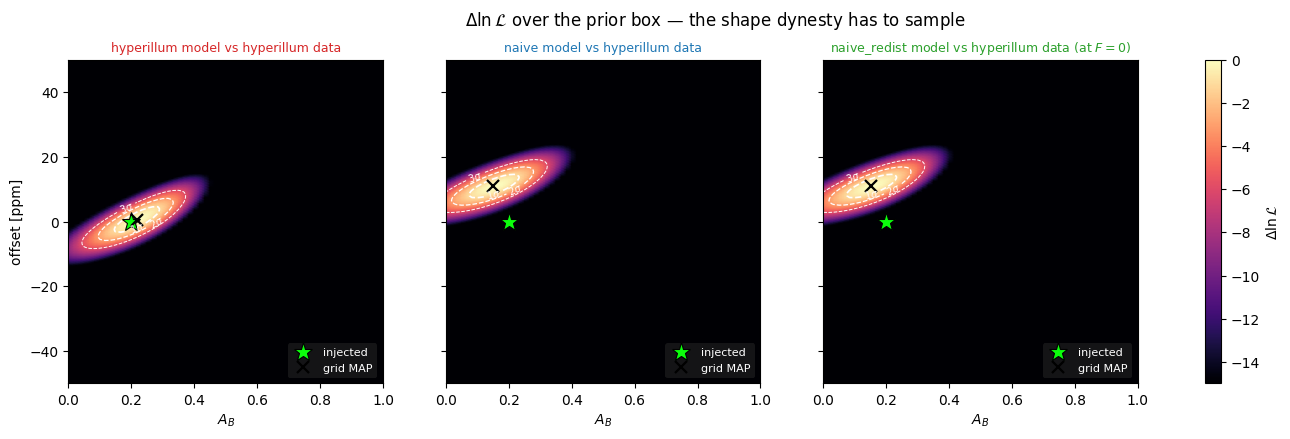

naive_redist 1271 forward models in 5.4 s   grid MAP: A_B = 0.0750, F = 0.0041, lnL = -90.201   (offset profiled out)


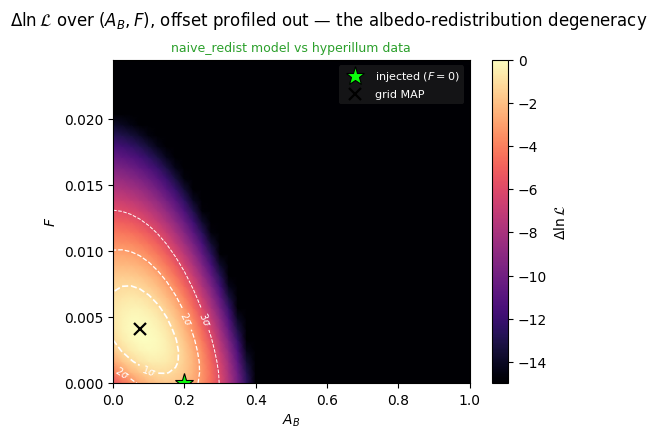

In [7]:
# (A_B, offset) maps: every model side by side, on a shared colour scale
lnL_maps = {}
for name, L in logls.items():
    t0 = time.perf_counter()
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name:12s} {len(A_grid)} forward models in {time.perf_counter()-t0:.1f} s   (caches: {L.cache_used})   grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.2f}")

fig, axes = plt.subplots(1, len(lnL_maps), figsize=(5.75 * len(lnL_maps), 4.2), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, 0., "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those are the colours of naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data" + (" (at $F = 0$)" if name in F_MODELS else ""), fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: all panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty has to sample", y=1.0)
plt.show()

# (A_B, F) map of the redistributing model, offset profiled out
lnL_maps_F = {}
if F_MODELS:
    A_gridF, F_gridF = pset.grid("A_B", 41), np.linspace(*F_LIM, 31)   # the same F zoom as the slice panel
    for name in F_MODELS:
        t0 = time.perf_counter()
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} {lnL.size} forward models in {time.perf_counter()-t0:.1f} s   grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$"); ax.set_ylabel("$F$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    plt.show()


## 3. Nested sampling

In [8]:
# pfrac=0 -> all sampling effort on lnZ (for the Bayes factor; run_dynesty.py uses pfrac=0.8, i.e. the posterior). The pickles go to dynesty_results/test/, apart from run_dynesty.py's.
sampler = dict(dynamic=True, pfrac=0.0, nlive=500, nlive_batch=250, maxbatch=10, dlogz=0.01, nprocs=12)
tag = dataset_tag(cfg.planet, instrument, cfg.sigma_1min, A_label=A_model.label, A_B=A_B_true, n_bins=n_bins, n_orbits=n_orbits, seed=seed, pfrac=sampler["pfrac"])   # the dataset tag, as run_dynesty.py writes it
scfg = {m: SamplerConfig(seed=seed, outfile=f"dynesty_results/test/{tag}_{{insolation_model}}_priors-{'+'.join(PSETS[m].names)}.pkl", **sampler) for m in MODELS}

fits = {m: run_nested_fit(L, PSETS[m], scfg[m]) for m, L in logls.items()}   # dynesty Results in fits[m].results



hyperillum: lnZ = -95.1239 +/- 0.0959,  22791 calls, 6.9 min (18 ms/call)
   CONVERGED | stop 0.959, 0/10 batches, ESS 1946
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed42_pfrac0_hyperillum_priors-A_B+offset.pkl



naive: lnZ = -97.2528 +/- 0.0962,  23331 calls, 9.9 min (26 ms/call)
   CONVERGED | stop 0.962, 0/10 batches, ESS 1966
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed42_pfrac0_naive_priors-A_B+offset.pkl



naive_redist: lnZ = -100.0968 +/- 0.0958,  105089 calls, 22.1 min (13 ms/call)
   CONVERGED | stop 0.958, 6/10 batches, ESS 5490
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed42_pfrac0_naive_redist_priors-A_B+offset+F.pkl


### 3.1 Evidence & Bayes factor
With two free parameters the evidence is just a 2-D integral, so it can be computed directly (brute force) for comparison:
$$Z=\int \mathcal{L}(\theta)\,\pi(\theta)\,\mathrm{d}\theta,\qquad \pi=\text{const}=\prod_k (\mathrm{hi}_k-\mathrm{lo}_k)^{-1}$$
For `naive_redist` the integral is 3-D: the offset axis stays analytic (one forward model per $(A_B, F)$ node), and the $F$ axis is sampled quadratically dense towards $F = 0$, where the whole likelihood sits. Its `edge` ratio is of order unity by construction — the likelihood peaks within a few $10^{-3}$ of the $F = 0$ boundary of the prior — which is the physical truncation, not a sign of a too-narrow prior; for the two other models a large `edge` would mean the prior, not the data, bounds $A_B$.


In [9]:
print(f"{'model':12s} {'NS lnZ':>18s} {'brute force':>12s} {'dlnZ':>9s} {'ncall':>8s} {'edge':>9s}")
for name, fit in fits.items():
    if "F" in PSETS[name].names:   # 3-D: one (offset x A_B) grid per F node; the F nodes are quadratically dense towards 0, where the likelihood is
        F_fine = F_BOUNDS[0] + (F_BOUNDS[1] - F_BOUNDS[0]) * np.linspace(0., 1., 201) ** 2
        lnLf = np.stack([logl_grid(logls[name], "A_B", A_fine, "offset", O_fine, {**base, "F": F_}, n_jobs=N_JOBS) for F_ in F_fine])   # (n_F, n_off, n_A_B)
        lnZ_bf, edge = evidence_bruteforce(lnLf, [F_fine, O_fine, A_fine], bounds=[F_BOUNDS, OFFSET_BOUNDS, A_B_BOUNDS])
    else:
        lnLf = logl_grid(logls[name], "A_B", A_fine, "offset", O_fine, base, n_jobs=N_JOBS)   # 201 forward models per model; the offset axis is analytic
        lnZ_bf, edge = evidence_bruteforce(lnLf, [O_fine, A_fine], bounds=pset.bounds[::-1])   # reversed: logl_grid returns (y, x) = (offset, A_B)
    d = fit.meta["lnZ"] - lnZ_bf
    print(f"{name:12s} {fit.meta['lnZ']:10.4f} +/- {fit.meta['lnZ_err']:.4f} {lnZ_bf:12.4f} {d:+9.4f} "
          f"{fit.meta['ncall']:8d} {edge:9.1e}")
    fit.meta["lnZ_bruteforce"] = lnZ_bf

for den in [m for m in fits if m != INSOL_TRUTH]:
    lnB = fits[INSOL_TRUTH].meta["lnZ"] - fits[den].meta["lnZ"]
    err = np.hypot(fits[INSOL_TRUTH].meta["lnZ_err"], fits[den].meta["lnZ_err"])
    print(f"\nln B ({INSOL_TRUTH} vs {den}) = {lnB:+.3f} +/- {err:.3f}   ->  B = {np.exp(lnB):.3g}")
print("Jeffreys: |lnB| < 1 inconclusive, 1-2.5 substantial, 2.5-5 strong, > 5 decisive")
print("dlnZ should be <~ 0.1 and within logzerr; a large `edge` means the PRIOR, not the data, is bounding the parameters (expected of order 1 for naive_redist: the peak sits next to F = 0).")


model                    NS lnZ  brute force      dlnZ    ncall      edge


hyperillum     -95.1239 +/- 0.0959     -95.1842   +0.0603    22791   1.5e-04


naive          -97.2528 +/- 0.0962     -97.1931   -0.0597    23331   2.0e-02


naive_redist  -100.0968 +/- 0.0958     -99.9906   -0.1062   105089   4.7e-01

ln B (hyperillum vs naive) = +2.129 +/- 0.136   ->  B = 8.41

ln B (hyperillum vs naive_redist) = +4.973 +/- 0.136   ->  B = 144
Jeffreys: |lnB| < 1 inconclusive, 1-2.5 substantial, 2.5-5 strong, > 5 decisive
dlnZ should be <~ 0.1 and within logzerr; a large `edge` means the PRIOR, not the data, is bounding the parameters (expected of order 1 for naive_redist: the peak sits next to F = 0).


### 3.2 Quick look at the posterior

hyperillum   (ESS 1946, information 4.33 nats)
   A_B      =    0.2172 +0.0465 -0.0462   (mean 0.2169 +/- 0.0469, truth 0.2)
   offset   =    0.6134 +2.6229 -2.6240   (mean 0.5881 +/- 2.5959, truth 0)


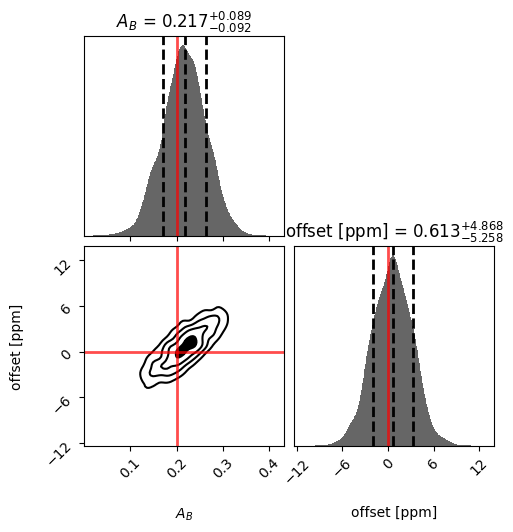

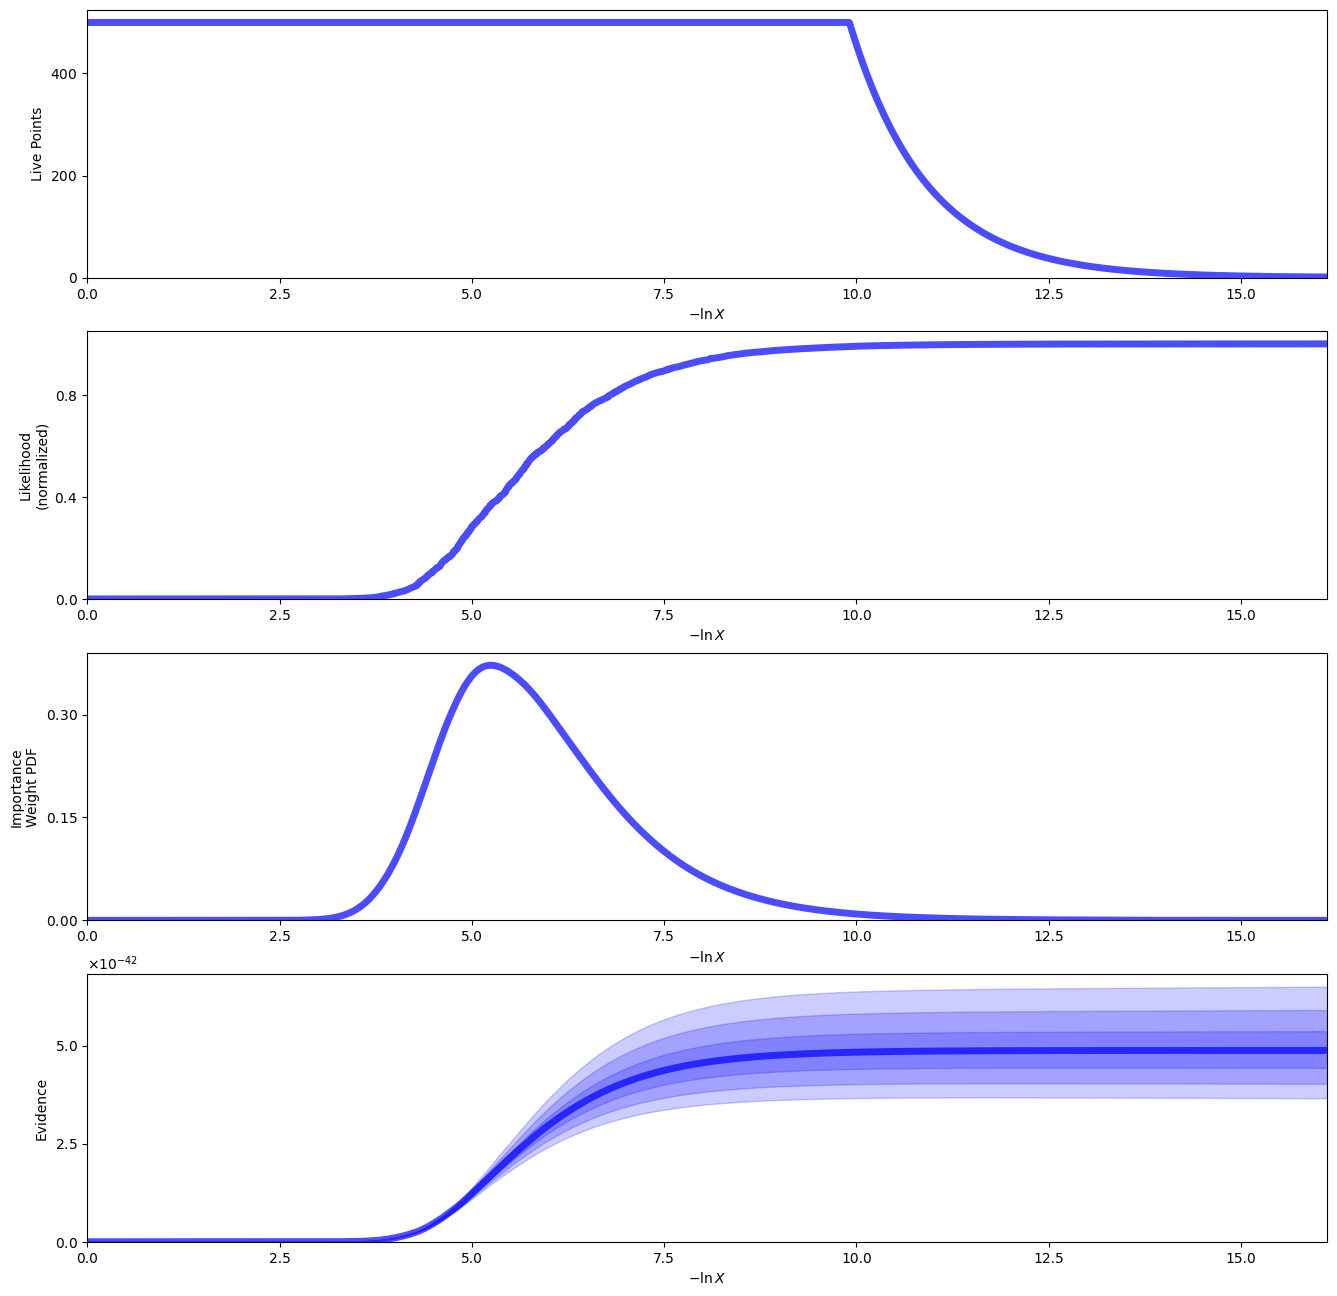

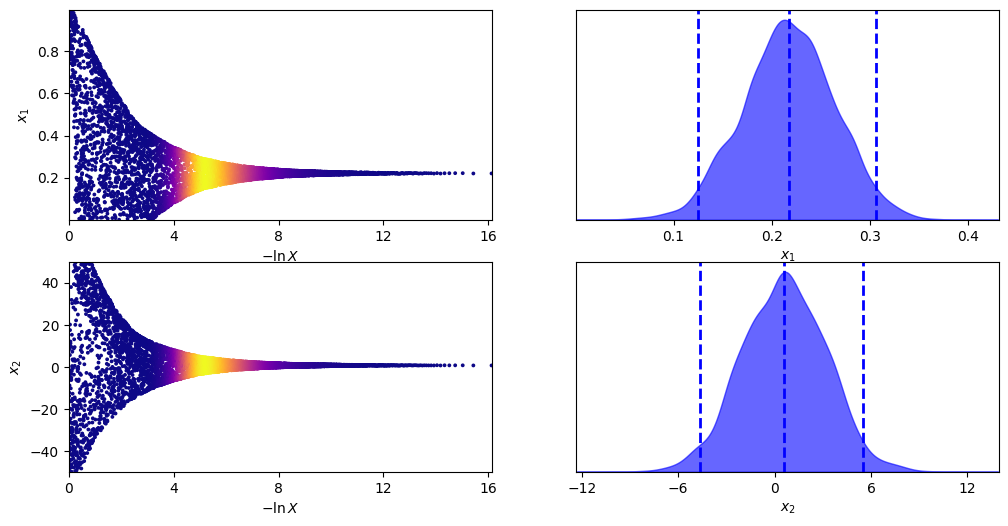

naive   (ESS 1966, information 4.35 nats)
   A_B      =    0.1510 +0.0531 -0.0533   (mean 0.1508 +/- 0.0525, truth 0.2)
   offset   =   10.8472 +2.3297 -2.3677   (mean 10.8664 +/- 2.3311, truth 0)


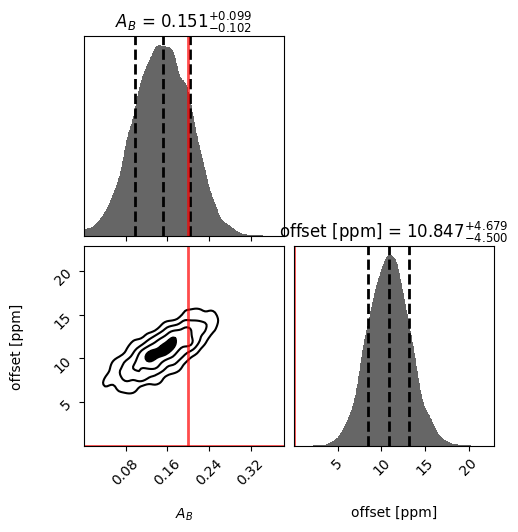

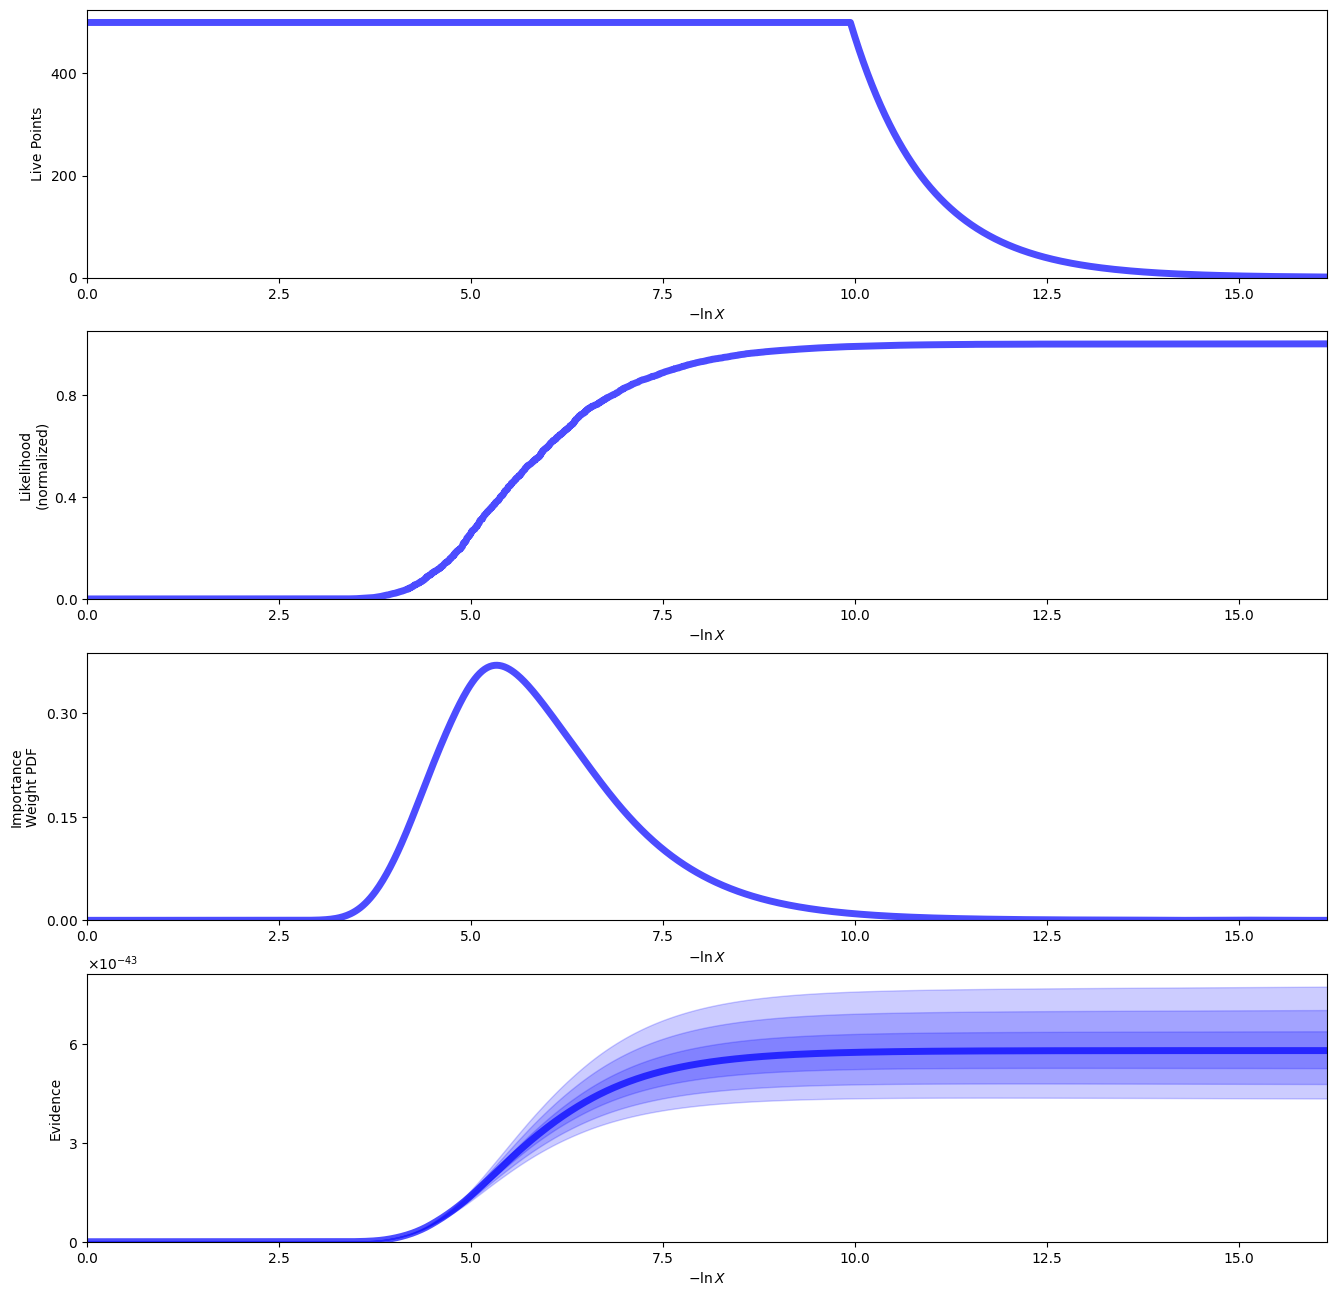

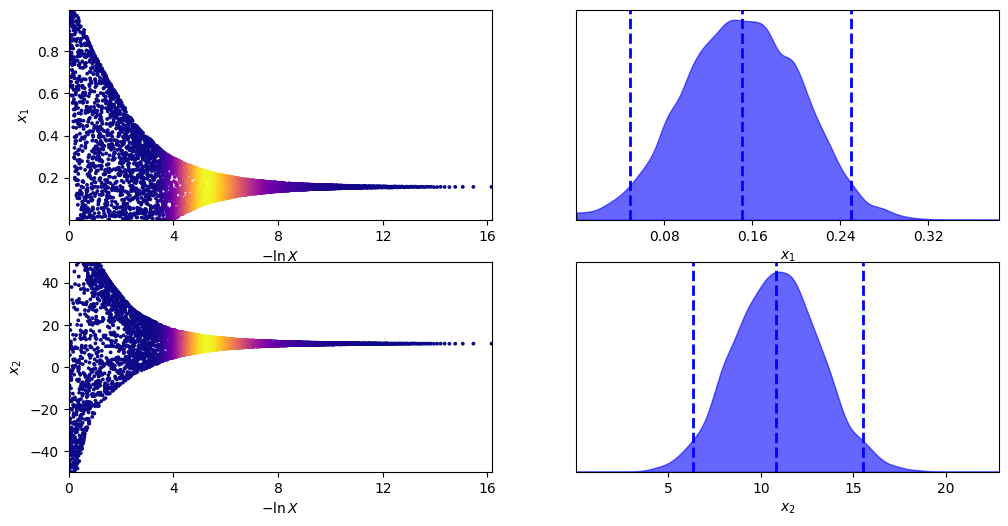

naive_redist   (ESS 5490, information 8.63 nats)
   A_B      =    0.0888 +0.0583 -0.0526   (mean 0.0924 +/- 0.0529, truth 0.2)
   offset   =    3.5517 +3.9935 -3.7869   (mean 3.6271 +/- 3.8249, truth 0)
   F        =    0.0039 +0.0022 -0.0018   (mean 0.0041 +/- 0.0020, truth 0)


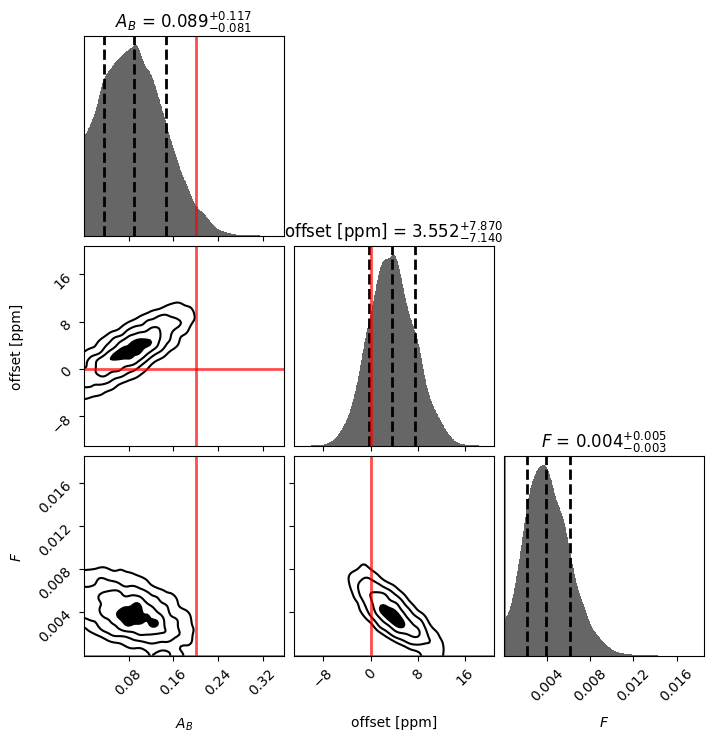

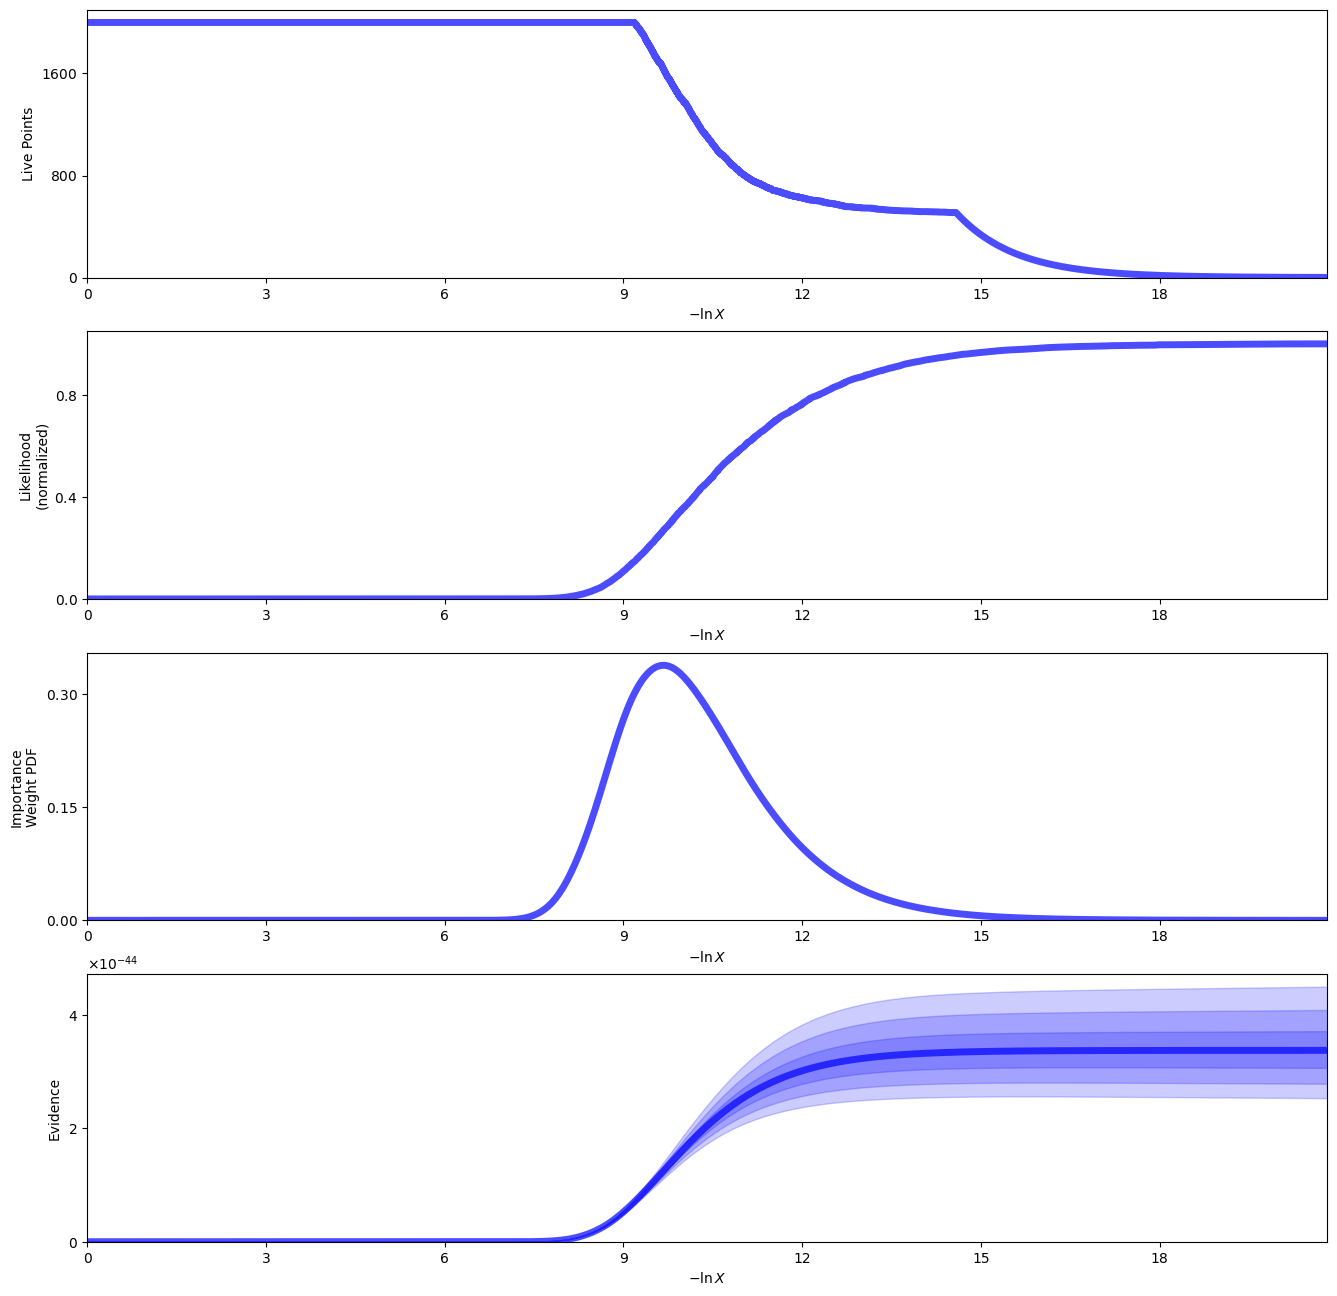

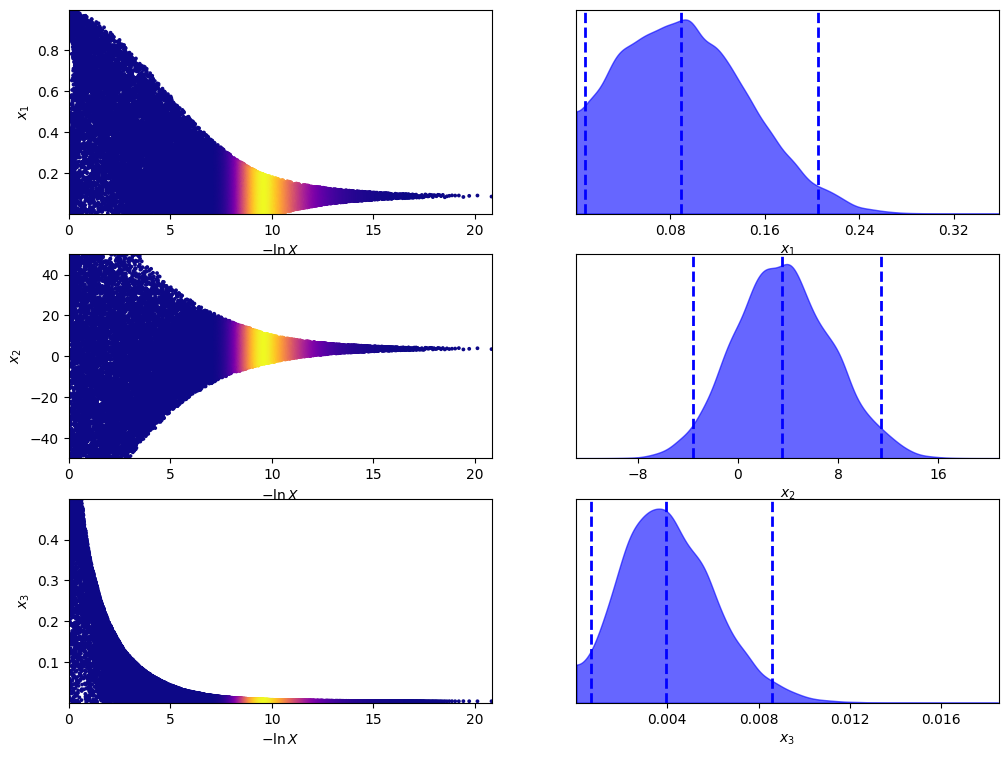

In [10]:
for name, fit in fits.items():
    # `res.samples` is NOT posterior-distributed: weight with `res.importance_weights()`, or take `res.samples_equal()` for plain draws.
    w = fit.results.importance_weights()
    mean, cov = dyfunc.mean_and_cov(fit.results.samples, w)
    print(f"{name}   (ESS {1./np.sum(w**2):.0f}, information {fit.meta['information']:.2f} nats)")
    for i, p in enumerate(fit.pset.names):
        lo, med, hi = dyfunc.quantile(fit.results.samples[:, i], [0.16, 0.50, 0.84], weights=w)
        print(f"   {p:8s} = {med:9.4f} +{hi-med:.4f} -{med-lo:.4f}   (mean {mean[i]:.4f} +/- {np.sqrt(cov[i,i]):.4f}, truth {base[p]:g})")

    dyplot.cornerplot(fit.results, labels=list(fit.pset.labels), truths=[base[p] for p in fit.pset.names], show_titles=True, title_fmt=".3f", quantiles=[0.16, 0.5, 0.84])
    plt.show()
    dyplot.runplot(fit.results); plt.show()
    dyplot.traceplot(fit.results); plt.show()


## 4. Posterior comparison

Everything below reuses `fits`, `logls`, `PSETS`, `base`, `COLOR` and `lnL_maps` from above. 4.1-4.2 are pure post-processing of the `Results` objects and cost **no** likelihood calls; 4.3-4.5 cost `N_DRAWS` forward models per insolation model.


### 4.1 Corner Plot

`res.samples` is ~uniform in $\ln X$, not posterior-distributed, so the density below is built from `res.samples_equal()`. Contours enclose 68% / 95% of the posterior *mass* (sort the cells by height, walk down until the mass is reached) - not Gaussian $\sigma$.

Dotted: the profile-likelihood contours from 2.2. With a uniform prior the likelihood map and the posterior differ only by the sampler's finite resolution, so a visible offset between dotted and filled contours is prior volume (Occam), not fit quality. For `naive_redist` the $(A_B, \mathrm{offset})$ contours are its *marginal* posterior (integrated over $F$) against the likelihood *slice* at $F = 0$, so they are wider than the dotted ones wherever $F$ is not pinned to 0; the $(A_B, F)$ plane is shown against the profile map from 2.2.


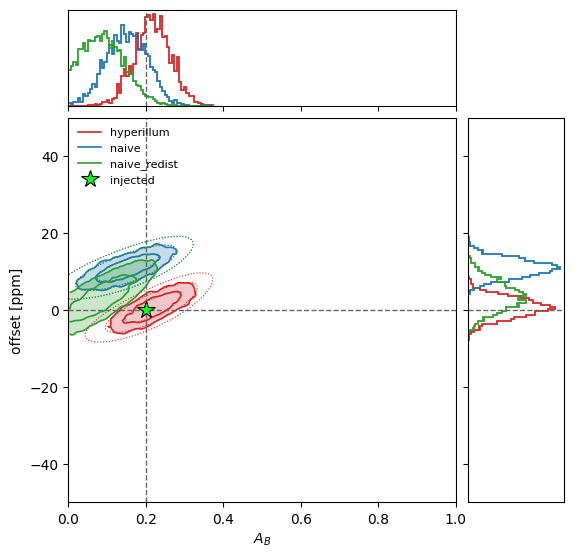

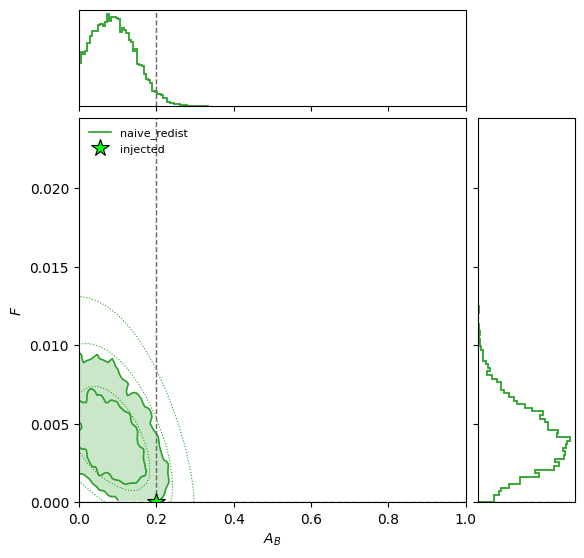

In [11]:
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
plt.show()

if F_MODELS:   # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of 2.2
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base, profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    plt.show()


### 4.2 Bias, degeneracy and the Bayes factor

`bayes_factor` quotes two errors. The analytic one is dynesty's `logzerr` added in quadrature; the jitter one is the spread of `jitter_run` realisations, which resample the prior-volume shrinkage $t_i\sim\mathrm{Beta}(N,1)$ that nested sampling only knows statistically - it needs no Gaussian assumption about either $\ln Z$.

hyperillum   ESS 1946, information 4.33 nats
   A_B      =    0.2172 +0.0465 -0.0462   truth 0.2, bias +0.0172 = +0.37 sigma
   offset   =    0.6134 +2.6229 -2.6240   truth 0, bias +0.6134 = +0.23 sigma
   corr(A_B, offset) = +0.804
naive   ESS 1966, information 4.35 nats
   A_B      =    0.1510 +0.0531 -0.0533   truth 0.2, bias -0.0490 = -0.92 sigma
   offset   =   10.8472 +2.3297 -2.3677   truth 0, bias +10.8472 = +4.62 sigma
   corr(A_B, offset) = +0.757
naive_redist   ESS 5490, information 8.63 nats
   A_B      =    0.0888 +0.0583 -0.0526   truth 0.2, bias -0.1112 = -2.01 sigma
   offset   =    3.5517 +3.9935 -3.7869   truth 0, bias +3.5517 = +0.91 sigma
   F        =    0.0039 +0.0022 -0.0018   truth 0, bias +0.0039 = +1.96 sigma
   corr(A_B, offset) = +0.742
   corr(A_B, F) = -0.375
   corr(offset, F) = -0.768
naive_redist: F < 0.0049 (68 %), F < 0.0077 (95 %)   [injected F = 0]


ln B (hyperillum vs naive) = +2.129 +/- 0.136 (analytic) +/- 0.138 (jitter, K=200)  ->  B = 8.41
P(sign of ln B secure) = 1.000  [sampler noise only, NOT a model probability]


ln B (hyperillum vs naive_redist) = +4.973 +/- 0.136 (analytic) +/- 0.114 (jitter, K=200)  ->  B = 144
P(sign of ln B secure) = 1.000  [sampler noise only, NOT a model probability]


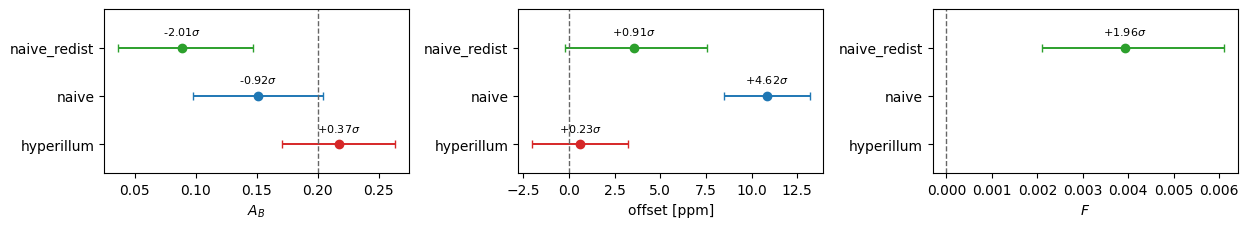

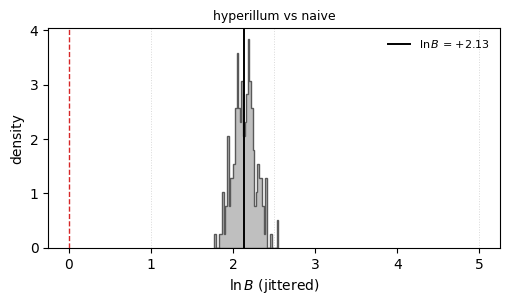

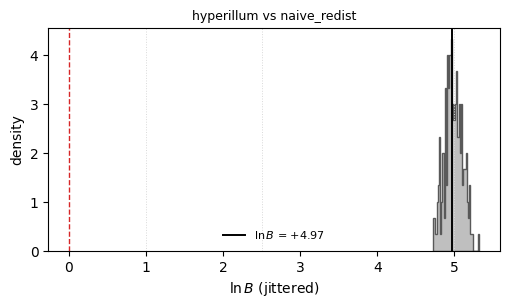

In [12]:
for f in fits.values(): posterior_summary(f, base)
for m in F_MODELS:   # F is one-sided against its F >= 0 prior: upper limits say more than a median +/- interval
    w, iF = fits[m].results.importance_weights(), PSETS[m].names.index("F")
    q68, q95 = dyfunc.quantile(fits[m].results.samples[:, iF], [0.68, 0.95], weights=w)
    print(f"{m}: F < {q68:.4f} (68 %), F < {q95:.4f} (95 %)   [injected F = {base['F']:g}]")

# lnB: "does this dataset contain enough information to distinguish the truth's model from each alternative?"
bfs = {m: bayes_factor(fits, INSOL_TRUTH, m, K=200) for m in fits if m != INSOL_TRUTH}

plot_bias(fits, base, colors=COLOR); plt.show()
for m, bf in bfs.items():
    fig, ax = plot_evidence_jitter(bf); ax.set_title(f"{INSOL_TRUTH} vs {m}", fontsize=9); plt.show()


### 4.3 Posterior predictive - and where in phase the evidence comes from

Bottom panel (one pair per figure: the truth's model against each alternative): the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases.


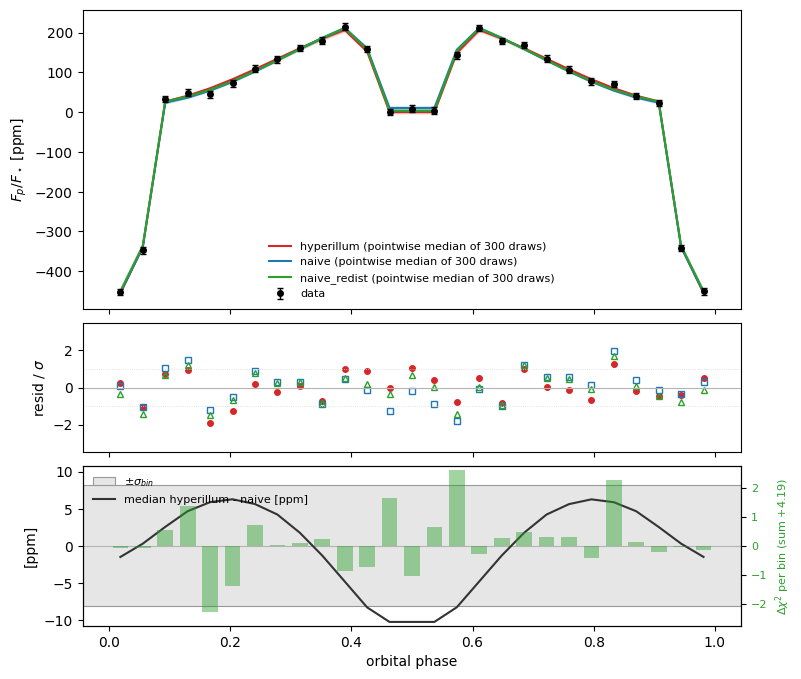

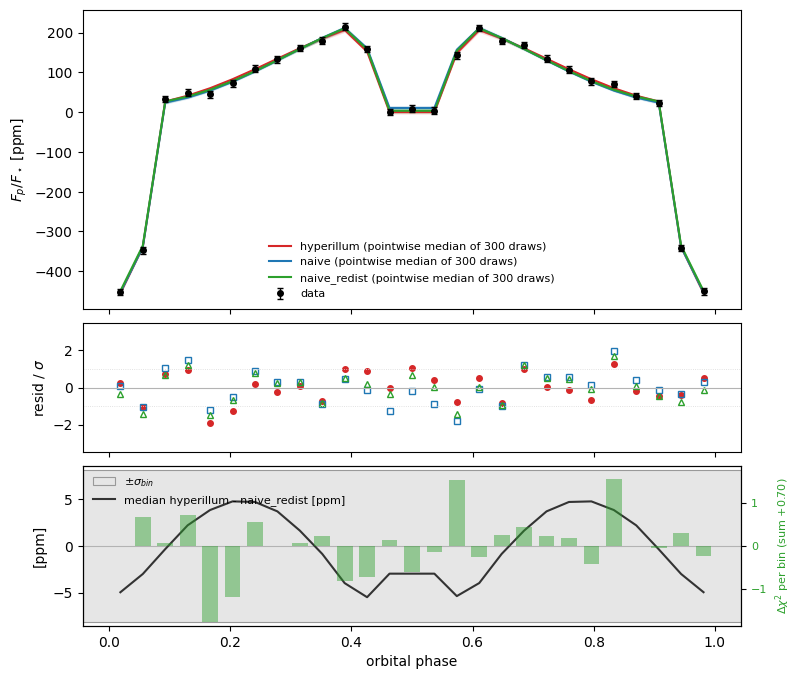

In [13]:
N_DRAWS = 300   # forward models per insolation model

for den in [m for m in fits if m != INSOL_TRUTH]:
    plot_posterior_predictive(logls, fits, num=INSOL_TRUTH, den=den, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
    plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.


### 4.4 Derived quantities

The posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model.
`T_term` > 0 for naive is an interpolation artefact: it is `np.interp` of the temperature grid at exactly 90°, between the last dayside and the first nightside node. The naive and hyperillum nightsides (`T_anti`) are exactly 0 K (drawn as lines); under `naive_redist` it is the redistributed nightside $T^4 \propto (1-A_B)\,F\,S/2$, the nightside temperature an observer would infer from a model that may redistribute heat, against a truth with none.

The first check compares `occultation_depth` of `pcurve_params` with the peak of the phase curve built from the same SPIDERMAN model: the phase-curve maximum lies below the depth, since at these $a/R_\star$ the occultation hides a range of phases and the visible maximum sits at ingress, not at full phase.


hyperillum   occultation_depth  232.30 ppm   phase-curve maximum  220.70 ppm
naive        occultation_depth  228.19 ppm   phase-curve maximum  212.89 ppm


naive_redist occultation_depth  228.19 ppm   phase-curve maximum  212.90 ppm


hyperillum   depth  236.3 +5.1 -5.8 ppm (thermal 230.0, reflected 6.3)   T_bright 2359.7 +34.9 -39.4 K
             T_sub 2690.2 K   T_term 1502.8 K   T_anti    0.0 K
naive        depth  239.1 +5.3 -5.1 ppm (thermal 232.9, reflected 6.2)   T_bright 2379.6 +36.5 -34.9 K
             T_sub 2731.6 K   T_term  551.6 K   T_anti    0.0 K
naive_redist depth  245.5 +4.9 -5.7 ppm (thermal 239.3, reflected 6.2)   T_bright 2423.1 +33.4 -38.7 K
             T_sub 2778.1 K   T_term  753.9 K   T_anti  582.9 K +76.4 -93.2 (< 705 K at 95 %)


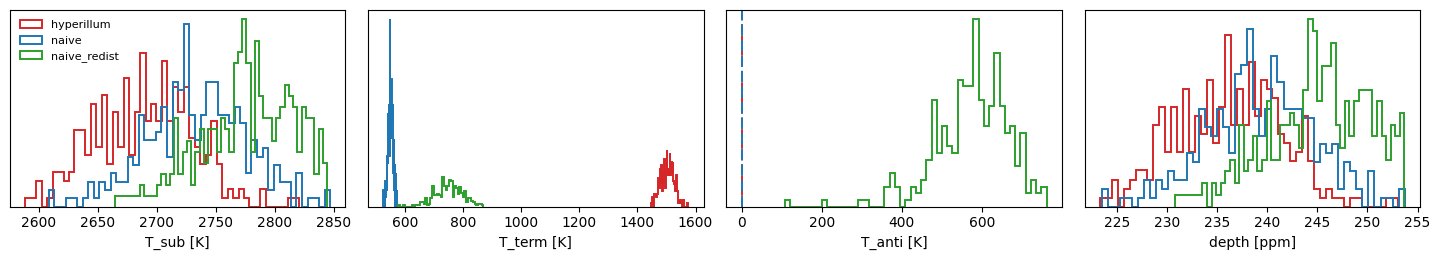

In [14]:
# Check of pcurve_params: for a thermal-only, transit-free config the occultation depth is close to the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
    _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=cfg.stellar_grid, emissivity=cfg_th.emissivity)
    print(f"{m:12s} occultation_depth {d_:7.2f} ppm   phase-curve maximum {y_.max():7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:12s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    Ta = np.percentile(d["T_anti"], [16, 50, 84, 95])
    print(f"{'':12s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {Ta[1]:6.1f} K" + (f" +{Ta[2]-Ta[1]:.1f} -{Ta[1]-Ta[0]:.1f} (< {Ta[3]:.0f} K at 95 %)" if name in F_MODELS else ""))

KEYS = ("T_sub", "T_term", "T_anti", "depth") if F_MODELS else ("T_sub", "T_term", "depth")
plot_derived(der, keys=KEYS, colors=COLOR); plt.show()


### 4.5 Noisy fit vs. the noiseless truth
Overlaid on the §1 truth:

- the dynesty **posterior medians** - what you would report from this one dataset, noise and all
- the misspecified model(s) fitted to the **noiseless** binned truth with the least-squares fits of the bias analysis (`simple_bias_analysis.fit_naive` for naive, the joint `fit_redist` in $(A_B, F)$ for naive_redist; offset free) - deterministic, no seed. **This is the bias.** For naive_redist the fitted $F$ is the false-positive redistribution, and the nightside temperature it implies is printed.
- the truth itself, the curve the data were drawn from

The bias is quoted in units of this seed's posterior width and of the Fisher $\sigma$ of the bias analysis (they agree where the posterior is Gaussian and not truncated by the prior), with the critical $\sigma_{1\,\rm min}$ at which it becomes a $1\sigma$ effect.

Lower panel: everything minus the binned truth, against $\pm\sigma_{\rm bin}$. Black points are the data, i.e. the noise the medians are chasing. The dotted grey line is the numerical floor - the *same* model at the *same* parameters, evaluated on the likelihood's coarser grid instead of the truth's. It should sit on zero; whatever it does is grid resolution, not physics, and it bounds how much of this figure can be believed.


hyperillum   median   A_B 0.2172 (+0.0172 = +0.37 sigma)   offset   +0.61 ppm (+0.61 = +0.23 sigma)   chi2 vs truth   0.12   vs data  16.83
             max-lnL  A_B 0.2199 (+0.0199)              offset   +0.65 ppm (+0.65)           chi2 vs truth   0.17   vs data  16.82
naive        median   A_B 0.1510 (-0.0490 = -0.92 sigma)   offset  +10.85 ppm (+10.85 = +4.62 sigma)   chi2 vs truth  12.75   vs data  21.02


             max-lnL  A_B 0.1560 (-0.0440)              offset  +11.02 ppm (+11.02)           chi2 vs truth  12.79   vs data  21.01
naive_redist median   A_B 0.0888 (-0.1112 = -2.01 sigma)   offset   +3.55 ppm (+3.55 = +0.91 sigma)   F 0.0039 (+0.0039)   chi2 vs truth   5.55   vs data  17.54
             max-lnL  A_B 0.0832 (-0.1168)              offset   +3.48 ppm (+3.48)   F 0.0037 (+0.0037)           chi2 vs truth   5.61   vs data  17.52

NOISELESS fit(s) to the NOISELESS truth  (offset free, no noise, no seed - this is THE bias; the least-squares fits of the bias analysis):
   naive        A_B 0.1412   bias -0.0588 = -1.11 sigma_A_B (posterior, this seed) = -1.11 sigma_Fisher   ->   dT_sub/T = +1.79 %
                |dA_B|/sigma_A_B = 1.11   ->   sigma_1min,crit = 69.5 ppm/min (posterior) / 69.7 ppm/min (Fisher)   (now 62.9, already finer: the bias is a 1.1 sigma effect at the delivered noise)
                offset absorbed +10.72 ppm    chi2 12.693  (squared truth-to-manifold di

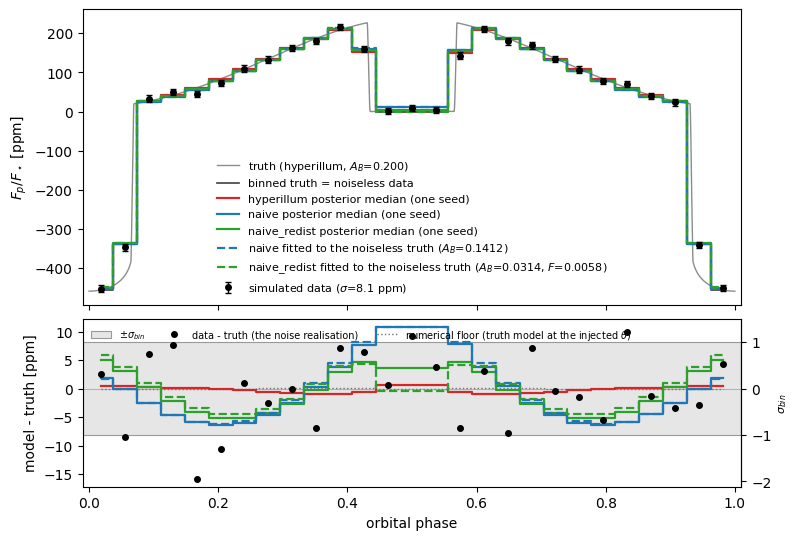

In [15]:
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH, colors=COLOR, verbose=True)   # the noiseless fits (the bias) in A_B_FIT_BOUNDS, as in the bias analysis
plt.show()
